# Curation notebook


In [104]:


import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from ephysSession import Session
import behavior
# from activitymode import Mode

cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 

In [362]:
path = r'G:\ephys_data\CW65\python\2025_02_25'
# path = r'K:\data\CW69\python\2025_12_19'
# path=r'H:\ephys_data\CW47\python\2024_10_20'

path = r'M:\data\CW75\python\2026_03_04'
path = r'M:\data\CW91\python\2026_05_04'
# path = r'M:\data\CW89\python\2026_05_20'
path = r'N:\data\CW98\python\2026_05_29'
path = r'N:\data\CW88\python\2026_06_06'
path = r'N:\\data\\CW98\\python\\2026_05_26' # Clear effect R dom

# path = r'N:\data\CW88\python\2026_06_11'
# path = r'J:\ephys_data\CW49\python\2024_12_16'
# path = r'G:\ephys_data\CW61\python\2025_03_18'
# path = r'G:\ephys_data\CW63\python\2025_03_25'

s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True,remove_consec_opto=False)
_, _, proportion_correct = s1.performance_in_trials(s1.i_good_trials)
# print(np.mean(correctarr))
print(proportion_correct)

Remove 0 trials from session for bad behavior
6 trials removed for stability reasons
only ppyr neurons: 213 --> 169
0.5955414012738853


In [363]:
s1.delay = 1.3 + 0.57
s1.response = 1.3 + 0.57 + 1.7

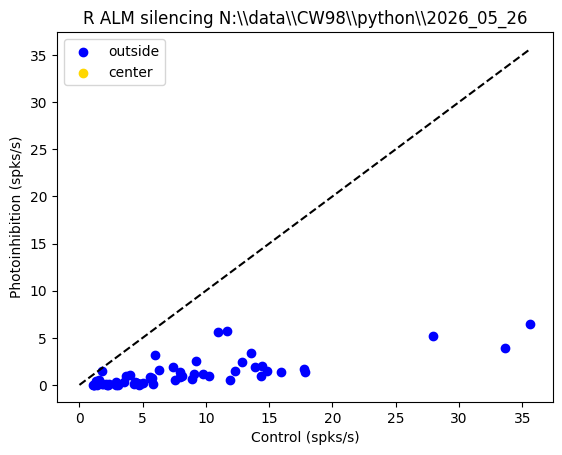

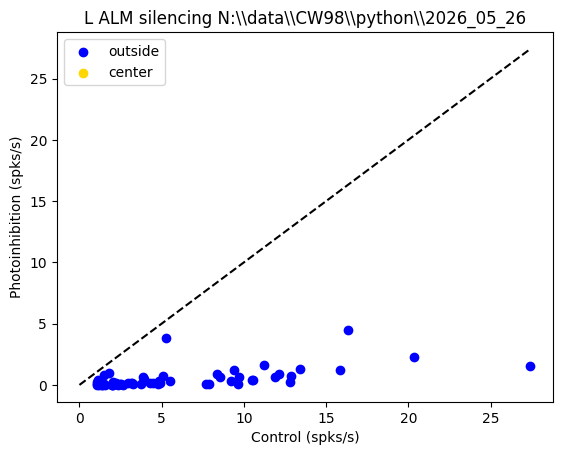

In [364]:
stim_spk, ctl_spk = [],[]
center_idx = []

sided_neurons = s1.good_neurons # s1.L_alm_idx
sided_neurons = s1.R_alm_idx
# stim_trials = s1.i_good_bi_stim_trials # s1.i_good_L_stim_trials
stim_trials = s1.i_good_R_stim_trials

window = (0.570 + 1.4 + 0, 0.570 + 1.4 + 1.0) # First second of delay
window = (0.570 + 1.3 + 0, 0.570 + 1.3 + 0.8) # First 0.8s of delay
counter = 0
for n in sided_neurons:
    # if s1.shank[n] == 1 or s1.shank[n] == 4:
    #     center_idx += [n]
    #     continue 
    ctl_rate = s1.get_spike_rate(n, window, s1.i_good_non_stim_trials)
    if ctl_rate < 1:
        continue
    stim_spk += [s1.get_spike_rate(n, window, stim_trials)]
    ctl_spk += [ctl_rate]
    
    if not hasattr(s1, 'shank'):
        # print("Warning: 's1.shank' attribute does not exist. Skipping center_idx classification.")
        center_idx += [counter]
        continue
    if s1.shank[n] == 2 or s1.shank[n] == 3:
        center_idx += [counter]
        
    counter += 1
    
    
f = plt.figure()
plt.scatter(ctl_spk, stim_spk, color='blue', label ='outside')
plt.scatter(np.array(ctl_spk)[center_idx], np.array(stim_spk)[center_idx], color='gold', label='center')
plt.plot([0, max(ctl_spk)], [0, max(ctl_spk)], ls='--', color='black')
plt.ylabel('Photoinhibition (spks/s)')
plt.xlabel('Control (spks/s)')
plt.title('R ALM silencing {}'.format(path))
plt.legend()
plt.show()



sided_neurons = s1.L_alm_idx
# stim_trials = s1.i_good_bi_stim_trials # s1.i_good_L_stim_trials
stim_trials = s1.i_good_L_stim_trials
stim_spk, ctl_spk = [],[]

counter = 0
for n in sided_neurons:
    # if s1.shank[n] == 1 or s1.shank[n] == 4:
    #     center_idx += [n]
    #     continue 
    ctl_rate = s1.get_spike_rate(n, window, s1.i_good_non_stim_trials)
    if ctl_rate < 1:
        continue
    stim_spk += [s1.get_spike_rate(n, window, stim_trials)]
    ctl_spk += [ctl_rate]
    if not hasattr(s1, 'shank'):
        # print("Warning: 's1.shank' attribute does not exist. Skipping center_idx classification.")
        center_idx += [counter]
        continue
    if s1.shank[n] == 2 or s1.shank[n] == 3:
        center_idx += [counter]
        
    counter += 1
    
    
f = plt.figure()
plt.scatter(ctl_spk, stim_spk, color='blue', label ='outside')
plt.scatter(np.array(ctl_spk)[center_idx], np.array(stim_spk)[center_idx], color='gold', label='center')
plt.plot([0, max(ctl_spk)], [0, max(ctl_spk)], ls='--', color='black')
plt.ylabel('Photoinhibition (spks/s)')
plt.xlabel('Control (spks/s)')
plt.title('L ALM silencing {}'.format(path))
plt.legend()
plt.show()


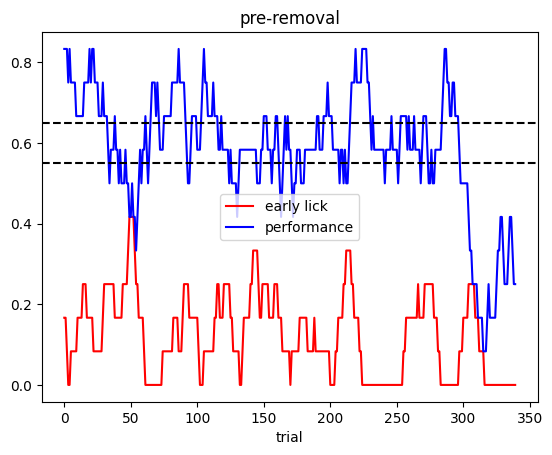

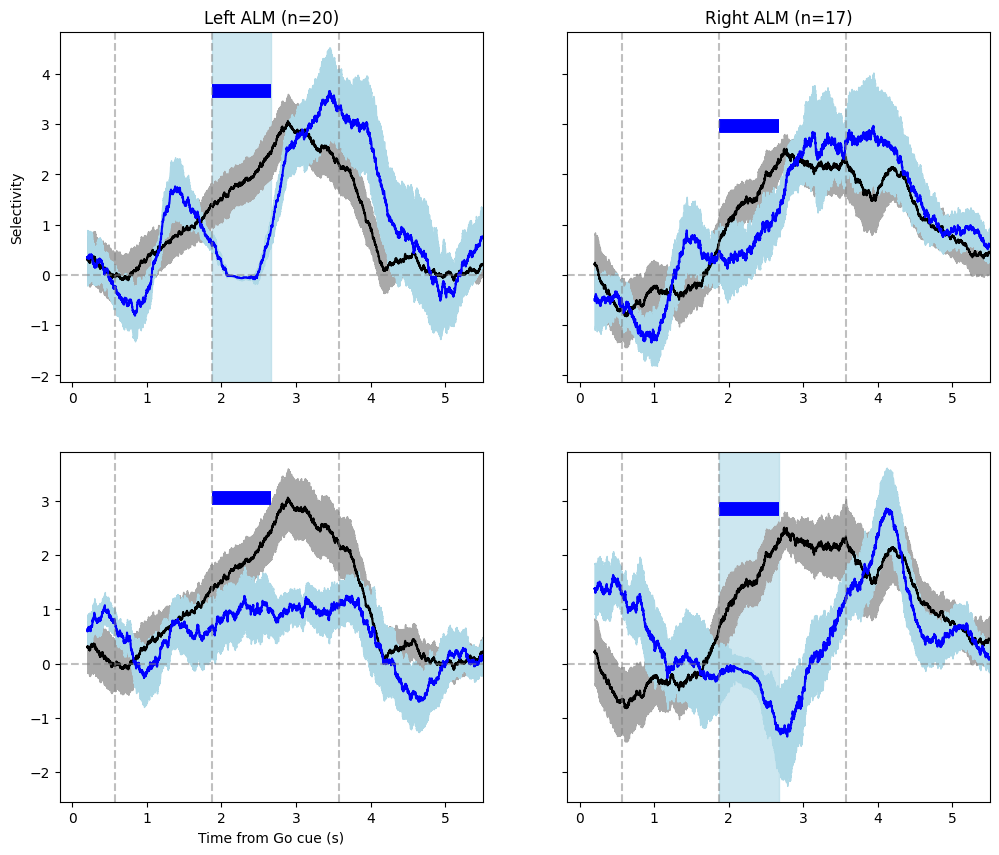

In [365]:
earlylick, correctarr, numtrials = s1.get_acc_conv(window=12, use_all_trials=True)

plt.plot(earlylick, 'r' ,label='early lick')

plt.plot(correctarr, 'b', label='performance')
# Overlay both earlylick and correctarr in green if belonging to s1.i_good_trials

# For each trial in i_good_trials, plot the corresponding points in green
good_trial_inds = s1.i_good_trials

# Plot earlylick values in green at good trial indices
# plt.plot(good_trial_inds, np.array(earlylick)[good_trial_inds], 'g', label='early lick (good trials)')

# Plot correctarr values in green at good trial indices
# plt.plot(good_trial_inds, np.array(correctarr)[good_trial_inds], 'g', label='performance (good trials)')

plt.axhline(0.55, color='k', linestyle='--')
plt.axhline(0.65, color='k', linestyle='--')
plt.xlabel('trial')
plt.title('pre-removal')
plt.legend()

# s1.delay, s1.response = 1.77, 3.47
# s1.delay, s1.response = 1.77, 3.47
epoch = (s1.delay+0.1, s1.response)
# epoch = (s1.sample, s1.delay)
# epoch = (1.77, 3.47)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01,
                                                    binsize=400, 
                                                    timestep=100,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)

Text(0.5, 1.0, 'post-removal')

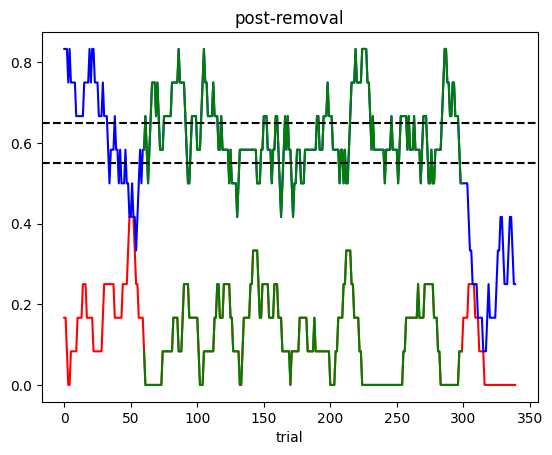

In [369]:
earlylick, correctarr, numtrials = s1.get_acc_conv(window=12, use_all_trials=True)

plt.plot(earlylick, 'r' ,label='early lick')

plt.plot(correctarr, 'b', label='performance')
# Overlay both earlylick and correctarr in green if belonging to s1.i_good_trials

# For each trial in i_good_trials, plot the corresponding points in green
good_trial_inds = np.concatenate([range(60,300),
                                # range(150,320),
                                # range(355,420),
                                # range(148, 205),
                                # range(217, 280),
                                # range(305, 390),
                                    ])
# good_trial_inds = np.load(s1.path + r'\good_trial_inds.npy')



# Plot earlylick values in green at good trial indices
plt.plot(good_trial_inds, np.array(earlylick)[good_trial_inds], 'g', label='early lick (good trials)')

# Plot correctarr values in green at good trial indices
plt.plot(good_trial_inds, np.array(correctarr)[good_trial_inds], 'g', label='performance (good trials)')

plt.axhline(0.55, color='k', linestyle='--')
plt.axhline(0.65, color='k', linestyle='--')
plt.xlabel('trial')
plt.title('post-removal')
# plt.legend()

In [370]:
# replace by new i_good_trials
_, _, proportion_correct = s1.performance_in_trials(good_trial_inds)
print(proportion_correct), s1.delay, s1.response

0.6208333333333333


(None, 1.87, 3.5700000000000003)

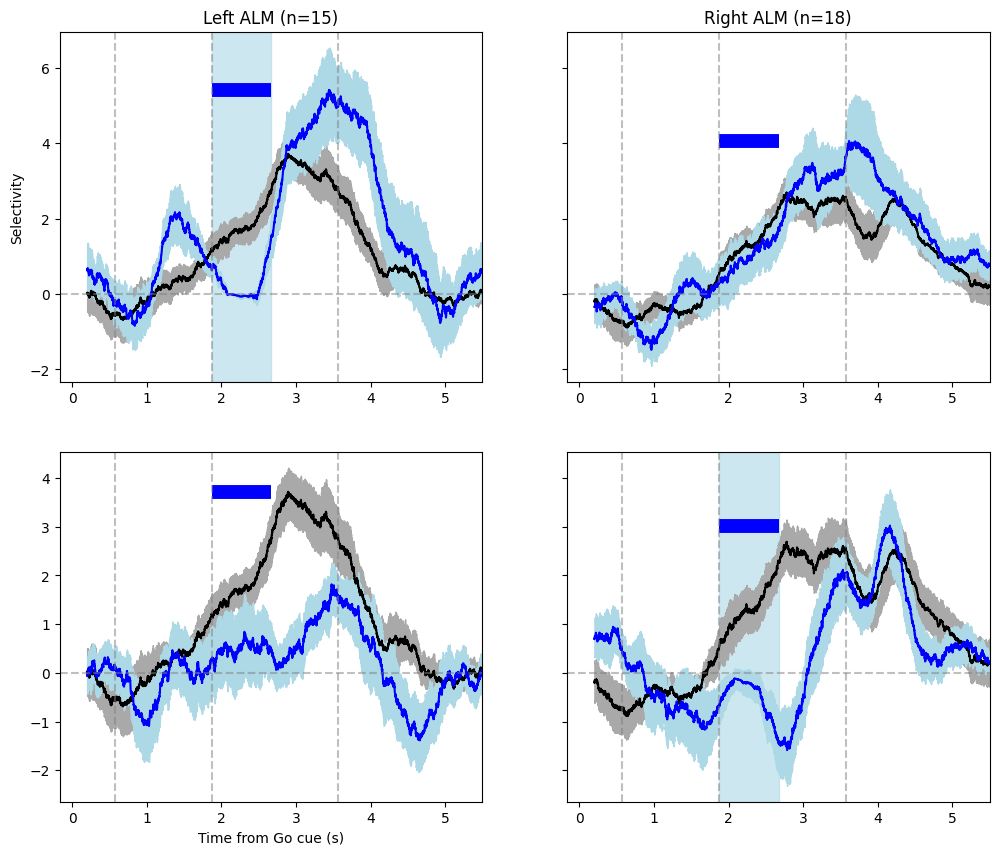

In [372]:
# Plot selectivity recovery to check
s1.i_good_trials = good_trial_inds
epoch = (s1.delay+0.1, s1.delay+1.7)
# epoch = (s1.sample, s1.delay)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01, 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)

# Save i good trials

np.save(s1.path + r'\good_trial_inds.npy', good_trial_inds)



In [69]:
# Look at single neurons
epoch = (s1.sample, s1.delay)
epoch = (s1.delay, s1.delay+1.7)
selective_neurons = s1.get_epoch_selective(epoch, p=0.01)

Remove 0 trials from session for bad behavior
14 trials removed for stability reasons
only ppyr neurons: 264 --> 216


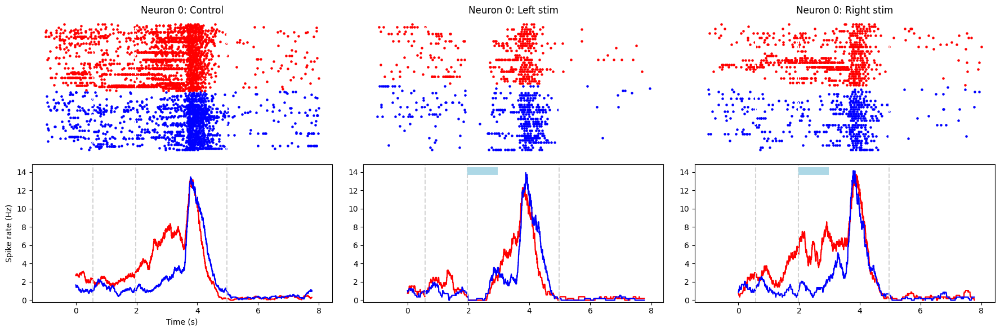

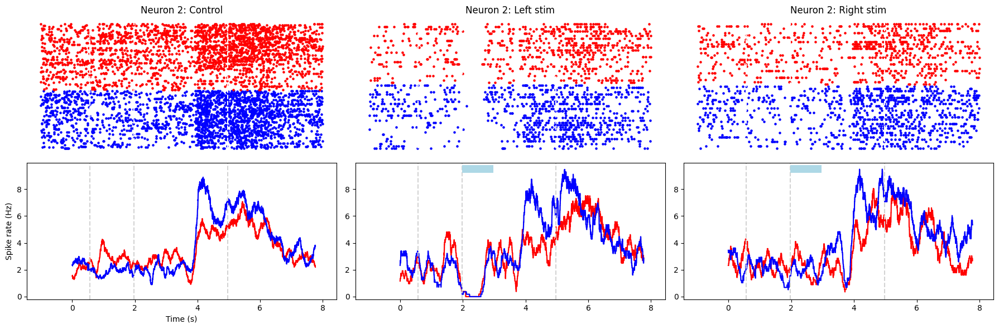

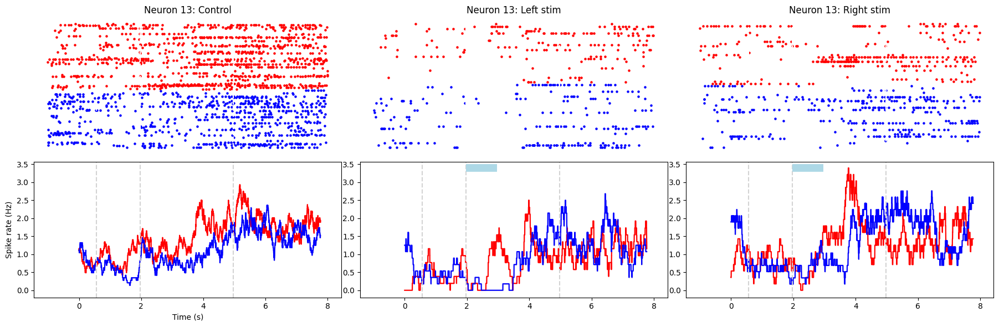

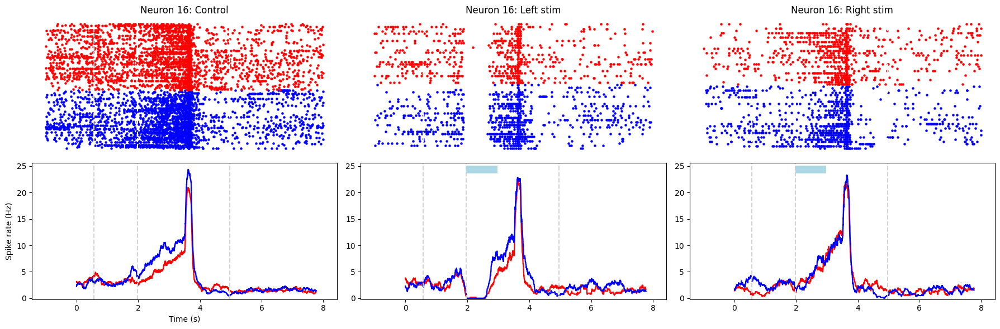

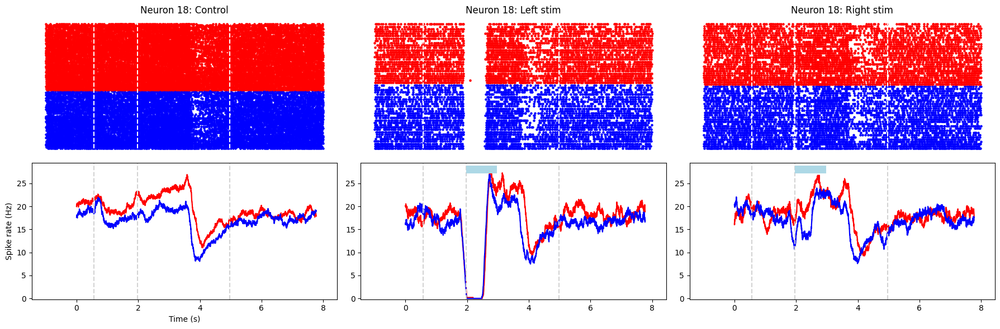

...

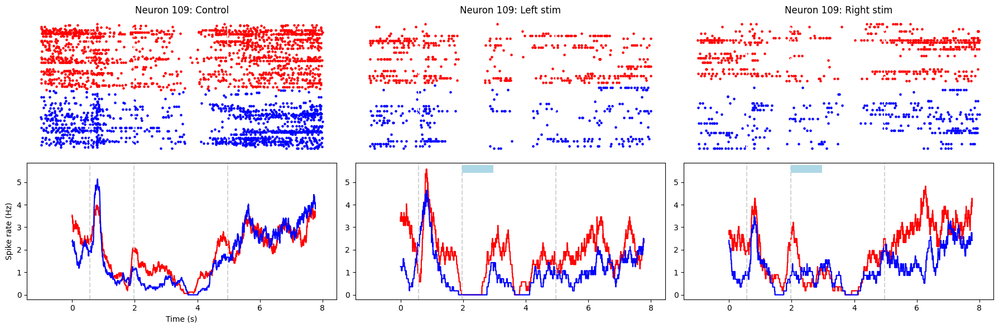

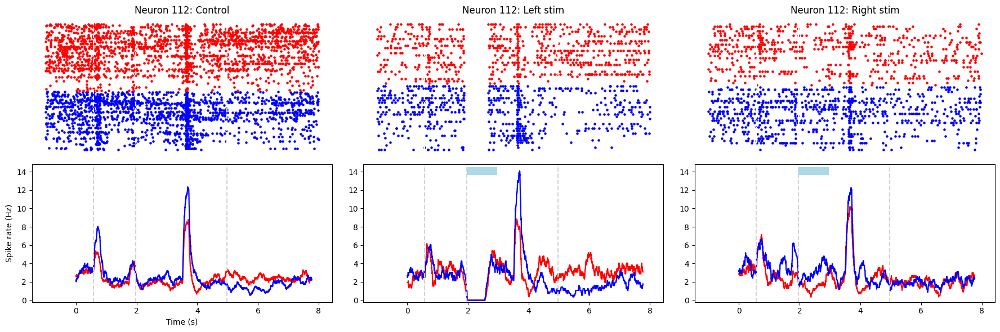

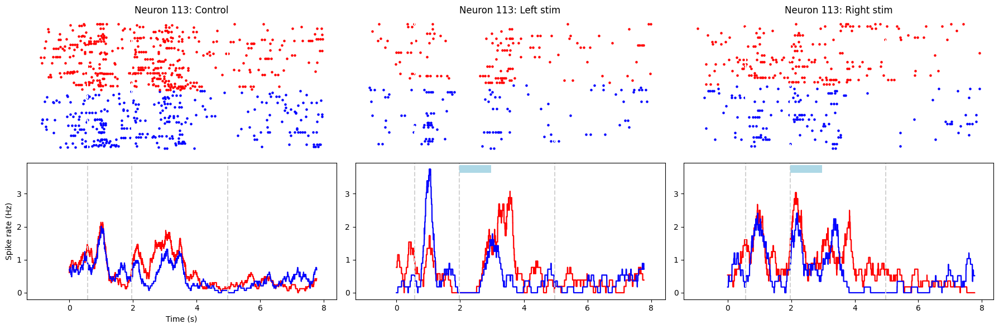

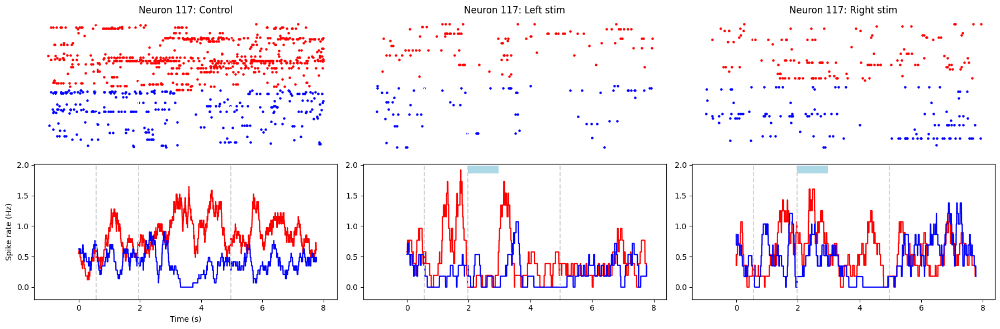

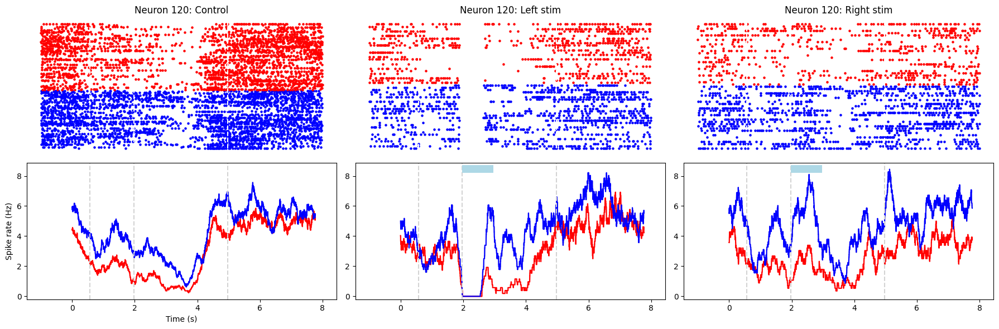

In [125]:

path = r'N:\data\CW98\python\2026_05_26'
s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
epoch = (s1.sample, s1.delay)
epoch = (s1.delay, s1.delay+1.7)
selective_neurons = s1.get_epoch_selective(epoch, p=0.05)
for n in [n for n in selective_neurons if n in s1.L_alm_idx]:
    s1.plot_raster_and_PSTH(n, opto=True, stimside='both')


## Red laser sessions

In [73]:
path = r'G:\ephys_data\CW65\python\2025_02_25'
# path = r'K:\data\CW69\python\2025_12_19'
# path=r'H:\ephys_data\CW47\python\2024_10_20'

path = r'K:\data\CW87\python\2026_02_22'
path = r'M:\data\CW75\python\2026_03_04'
path = r'K:\data\CW84\python\2026_03_20'
path = r'M:\data\CW80\python\2026_04_05'
path = r'G:\ephys_data\CW59\python\2025_02_27'
path = r'M:\data\CW91\python\2026_05_06'
path = r'M:\data\CW89\python\2026_05_16'
path = r'N:\data\CW98\python\2026_05_25'
path = r'N:\data\CW88\python\2026_06_09'

s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=False)
_, _, proportion_correct = s1.performance_in_trials(s1.i_good_trials)

s1.delay = 1.2 + 0.57
s1.response = 1.2 + 0.57 + 1.7
# print(np.mean(correctarr))
print(proportion_correct)

41 trials removed for stability reasons
only ppyr neurons: 190 --> 175
0.5548523206751055


Text(0.5, 1.0, 'post-removal')

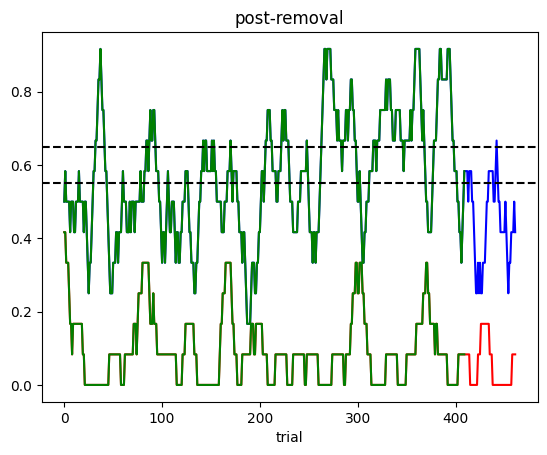

In [72]:
earlylick, correctarr, numtrials = s1.get_acc_conv(window=12)

plt.plot(earlylick, 'r' ,label='early lick')

plt.plot(correctarr, 'b', label='performance')
# Overlay both earlylick and correctarr in green if belonging to s1.i_good_trials

# For each trial in i_good_trials, plot the corresponding points in green
good_trial_inds = np.concatenate([range(0,410),
                                # range(209, 238),
                                # range(270, 297),
                                    ])
# good_trial_inds = np.load(s1.path + r'\good_trial_inds.npy')



# Plot earlylick values in green at good trial indices
plt.plot(good_trial_inds, np.array(earlylick)[good_trial_inds], 'g', label='early lick (good trials)')

# Plot correctarr values in green at good trial indices
plt.plot(good_trial_inds, np.array(correctarr)[good_trial_inds], 'g', label='performance (good trials)')

plt.axhline(0.55, color='k', linestyle='--')
plt.axhline(0.65, color='k', linestyle='--')
plt.xlabel('trial')
plt.title('post-removal')
# plt.legend()

In [63]:
# replace by new i_good_trials
_, _, proportion_correct = s1.performance_in_trials(good_trial_inds)
print(proportion_correct), s1.delay, s1.response

0.6170731707317073


(None, 1.77, 3.4699999999999998)

Remove 59 trials from session for bad behavior
41 trials removed for stability reasons
only ppyr neurons: 190 --> 175


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:226: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:261: RuntimeWarning: invalid value encountered in scalar divi

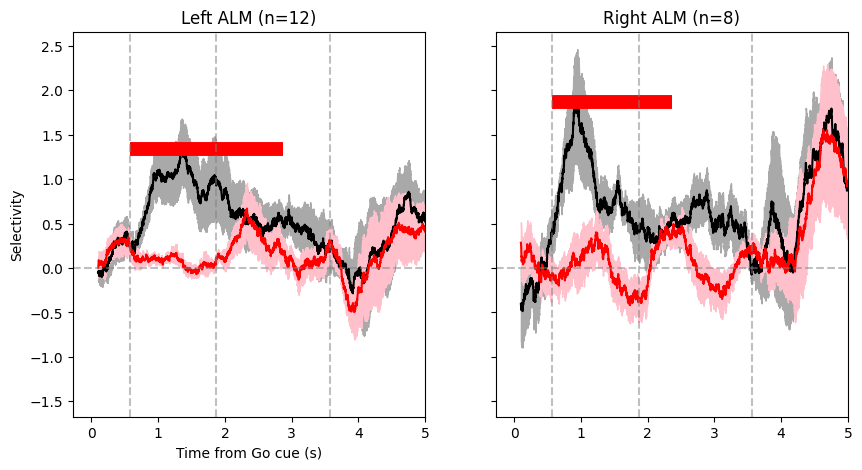

In [77]:
# path = r'M:\data\CW91\python\2026_05_06'
# path = r'M:\data\CW89\python\2026_05_16'
# path = r'N:\data\CW98\python\2026_05_25'

s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=False, laser='red')

s1.delay = 1.3 + 0.57
s1.response = 1.3 + 0.57 + 1.7

left_info, right_info = s1.selectivity_optogenetics(epoch = (s1.sample, s1.delay),
                                                    p=0.05, 
                                                    binsize=300, 
                                                    timestep=50,
                                                    bootstrap=True)

sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info

f, axarr = plt.subplots(1,2, sharey='row', figsize=(10,5))  

axarr[0].plot(time, sel, 'black')
        
axarr[0].fill_between(time, sel - err, 
          sel + err,
          color=['darkgray'])

axarr[1].plot(time, sel_R, 'black')
        
axarr[1].fill_between(time, sel_R - err_R, 
          sel_R + err_R,
          color=['darkgray'])
    
axarr[0].plot(time, selo_stimleft, 'red')
        
axarr[0].fill_between(time, selo_stimleft - erro_stimleft, 
          selo_stimleft + erro_stimleft,
          color=['pink'])       
axarr[0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.sample, xmax=s1.delay+1, linewidth=10, color='red')



axarr[1].plot(time, selo_stimleft_R, 'red')
        
axarr[1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
          selo_stimleft_R + erro_stimleft_R,
          color=['pink'])       
axarr[1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.sample, xmax=s1.delay+0.5, linewidth=10, color='red')


for i in range(2):
    axarr[i].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
    axarr[i].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
    axarr[i].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
    axarr[i].axhline(0, color = 'grey', alpha=0.5, ls = '--')
    axarr[i].set_xlim(right=5)


left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
axarr[0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
axarr[1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
axarr[0].set_xlabel('Time from Go cue (s)')
axarr[0].set_ylabel('Selectivity')
# plt.set_xlim(left=5)
# plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))

plt.show()

In [106]:
s1.stim_level

array([0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. ,
       0. , 0. , 0. , 2.7, 2.7, 2.7, 0. , 0. , 2.7, 2.7, 2.7, 2.7, 0. ,
       2.7, 0. , 0. , 0. , 2.7, 2.7, 2.7, 0. , 0. , 0. , 0. , 2.7, 2.7,
       0. , 0. , 0. , 2.7, 0. , 0. , 0. , 0. , 0. , 2.7, 0. , 0. , 0. ,
       2.7, 2.7, 0. , 0. , 2.7, 0. , 0. , 0. , 2.7, 0. , 0. , 2.7, 0. ,
       0. , 0. , 2.7, 2.7, 0. , 2.7, 2.7, 2.7, 0. , 0. , 2.7, 2.7, 2.7,
       0. , 0. , 2.7, 2.7, 2.7, 2.7, 0. , 0. , 2.7, 0. , 0. , 0. , 2.7,
       0. , 0. , 2.7, 0. , 2.7, 0. , 2.7, 0. , 2.7, 2.7, 2.7, 0. , 0. ,
       0. , 2.7, 2.7, 2.7, 0. , 2.7, 2.7, 0. , 2.7, 0. , 0. , 0. , 2.7,
       2.7, 2.7, 0. , 0. , 0. , 0. , 2.7, 0. , 2.7, 2.7, 0. , 0. , 2.7,
       2.7, 0. , 0. , 0. , 0. , 0. , 0. , 2.7, 2.7, 0. , 0. , 2.7, 2.7,
       0. , 2.7, 0. , 0. , 0. , 2.7, 0. , 2.7, 2.7, 2.7, 0. , 0. , 2.7,
       0. , 0. , 2.7, 2.7, 2.7, 0. , 0. , 0. , 2.7, 2.7, 2.7, 0. , 2.7,
       0. , 0. , 0. , 2.7, 2.7, 0. , 0. , 2.7, 2.7, 0. , 2.7, 2.

In [126]:
s1.path, s1.delay, s1.response

('M:\\data\\CW91\\python\\2026_05_04', 1.87, 3.5700000000000003)

In [76]:
s1.i_good_trials
s1.i_good_L_stim_trials = np.where(s1.stim_ON == 1)[0]
s1.i_good_R_stim_trials = []
s1.stim_side[s1.stim_ON] = 'L'


In [108]:
epoch = (s1.sample, s1.delay)
epoch = (s1.delay, s1.response)
selective_neurons = s1.get_epoch_selective(epoch, p=0.05)

In [109]:
[n for n in selective_neurons if n in s1.L_alm_idx]

[3,
 7,
 9,
 11,
 13,
 16,
 17,
 19,
 25,
 30,
 32,
 38,
 40,
 45,
 49,
 50,
 52,
 57,
 59,
 60,
 63,
 66,
 75,
 77,
 79,
 80,
 89,
 90,
 95,
 96,
 100,
 101]

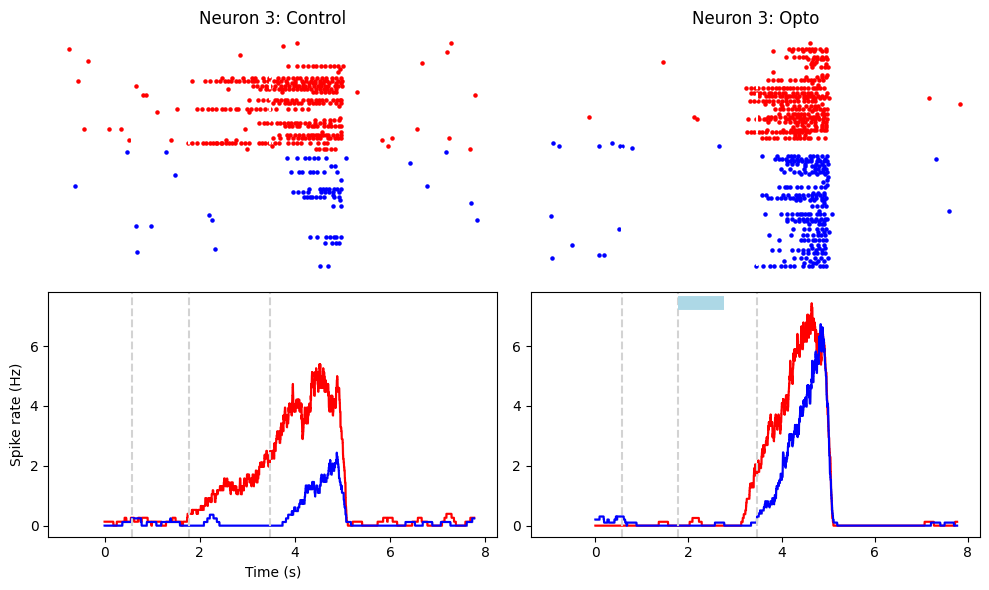

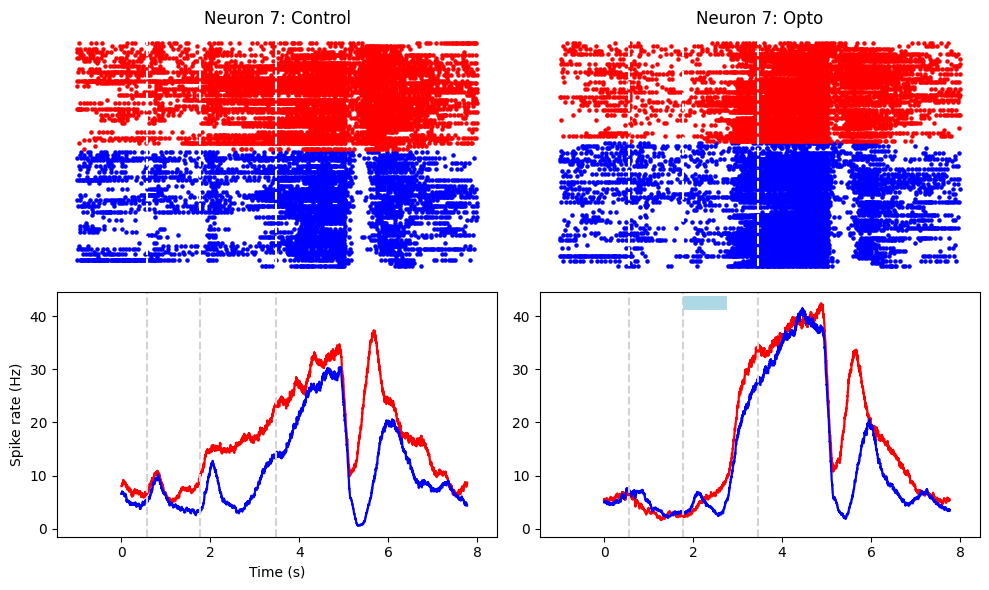

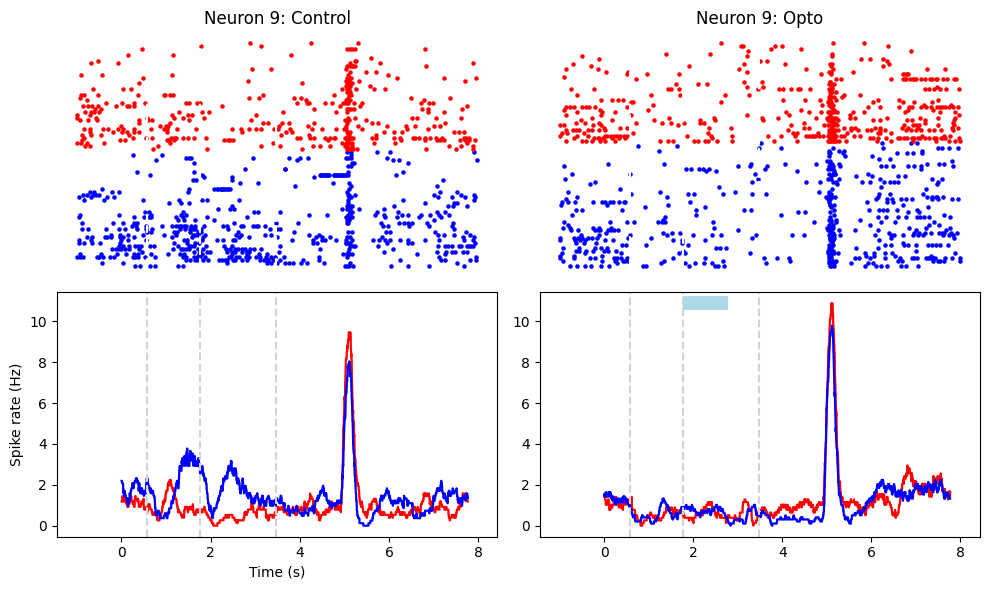

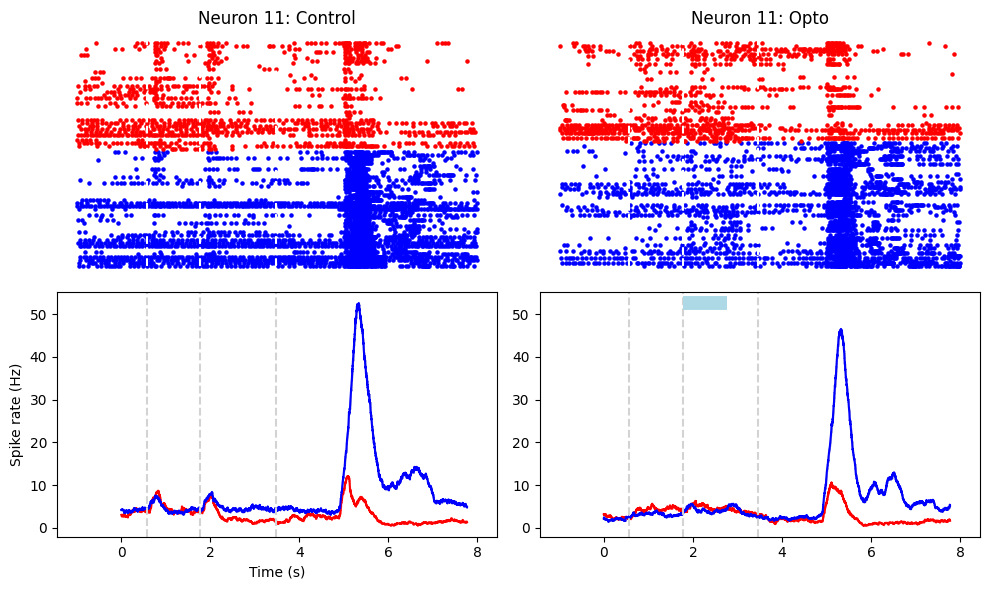

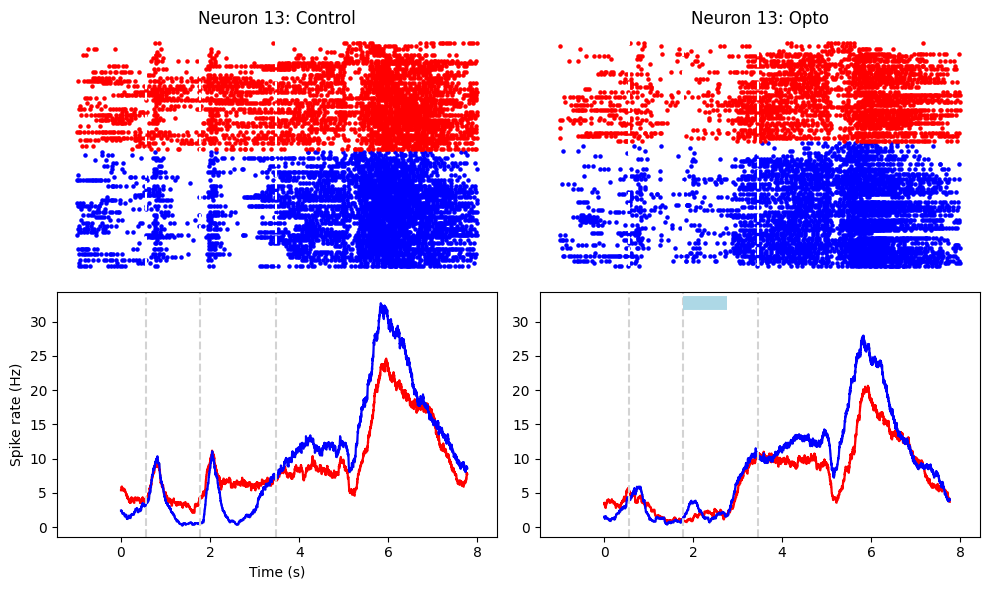

...

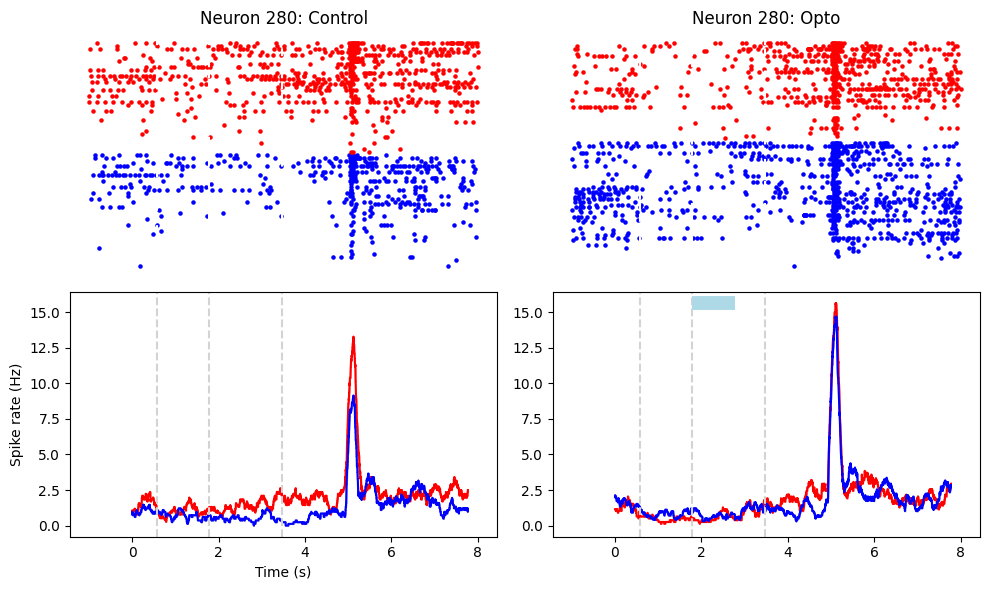

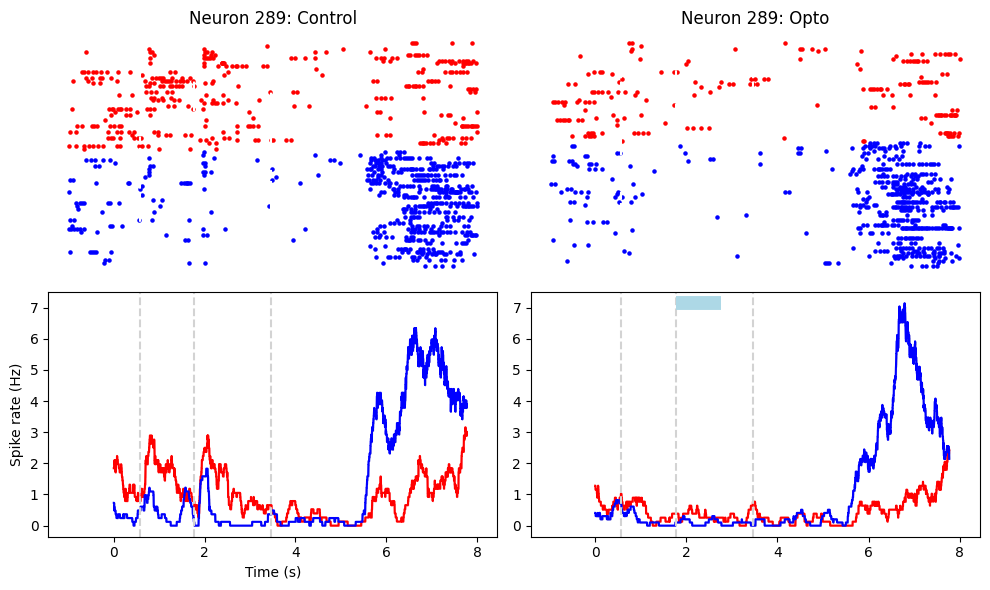

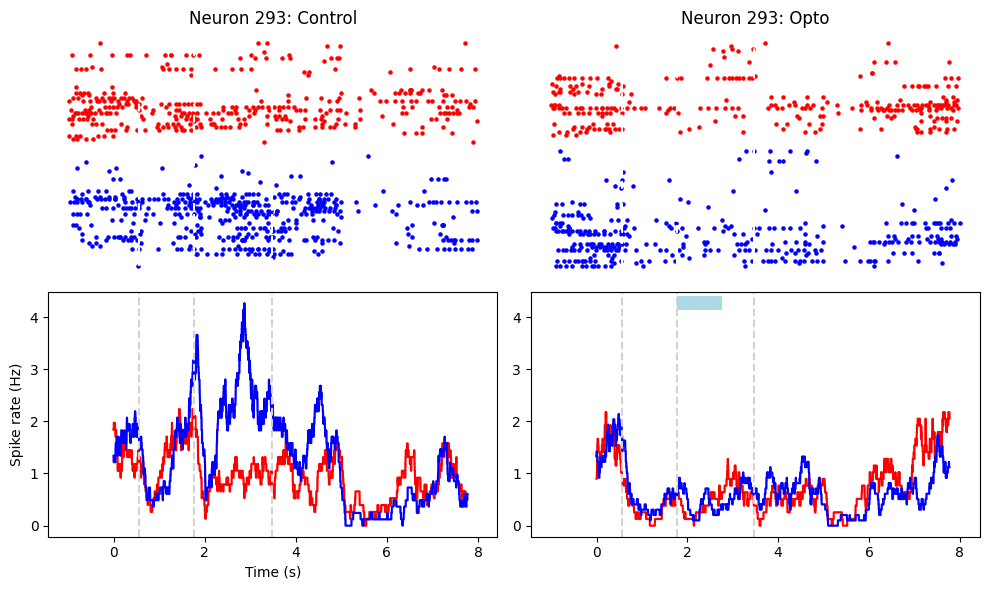

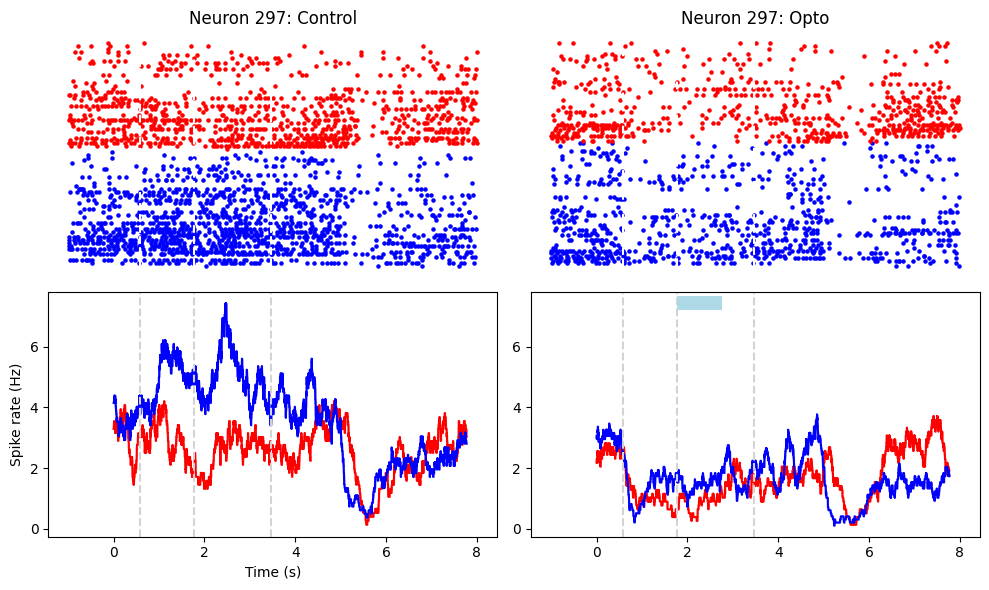

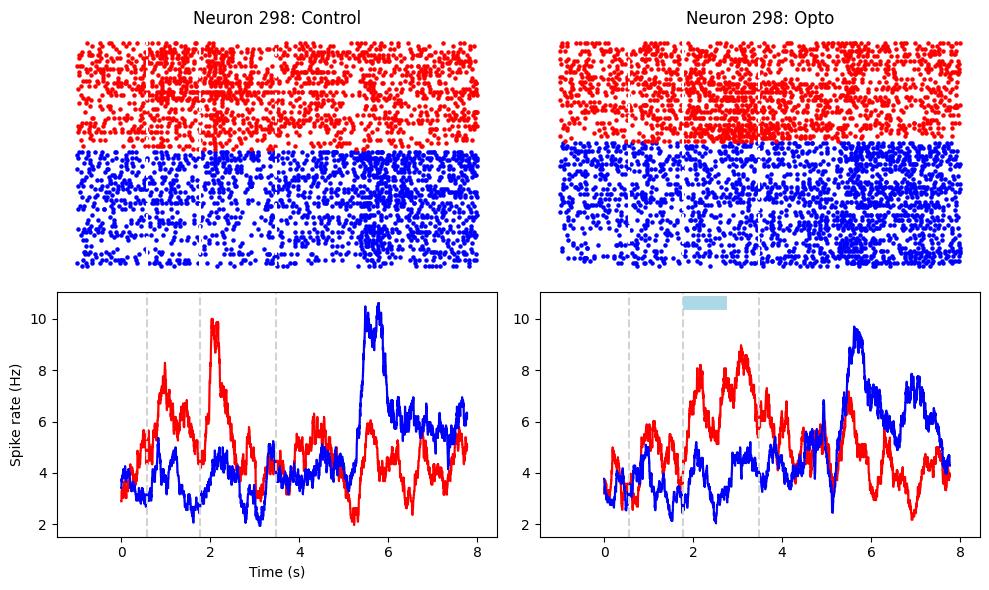

In [110]:
for n in selective_neurons:
    s1.plot_raster_and_PSTH(n, opto=True, stimside='L')

## Functions

In [7]:
def plot_selectivity_recovery(s1, left_info, right_info):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(2,2, sharey='row', figsize=(12,10))  
    axarr[0,0].axvspan(s1.delay, s1.delay+0.8, color='lightblue', alpha=0.6)
    axarr[1,1].axvspan(s1.delay, s1.delay+0.8, color='lightblue', alpha=0.6)

    for i in range(2):
        axarr[i,0].plot(time, sel, 'black')
                
        axarr[i,0].fill_between(time, sel - err, 
                  sel + err,
                  color=['darkgray'])
    
        axarr[i,1].plot(time, sel_R, 'black')
                
        axarr[i,1].fill_between(time, sel_R - err_R, 
                  sel_R + err_R,
                  color=['darkgray'])
        
    axarr[0,0].plot(time, selo_stimleft, 'blue')
            
    axarr[0,0].fill_between(time, selo_stimleft - erro_stimleft, 
              selo_stimleft + erro_stimleft,
              color=['lightblue'])       
    axarr[0,0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    
    axarr[1,0].plot(time, selo_stimright, 'blue')
            
    axarr[1,0].fill_between(time, selo_stimright - erro_stimright, 
              selo_stimright + erro_stimright,
              color=['lightblue'])      
    axarr[1,0].hlines(y=max(cat((selo_stimright, sel))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    
    axarr[0,1].plot(time, selo_stimleft_R, 'blue')
            
    axarr[0,1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
              selo_stimleft_R + erro_stimleft_R,
              color=['lightblue'])       
    axarr[0,1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    axarr[1,1].plot(time, selo_stimright_R, 'blue')
            
    axarr[1,1].fill_between(time, selo_stimright_R - erro_stimright_R, 
              selo_stimright_R + erro_stimright_R,
              color=['lightblue'])      
    axarr[1,1].hlines(y=max(cat((selo_stimright_R, sel_R))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    
    
    for i in range(2):
        for j in range(2):
            axarr[i,j].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axhline(0, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].set_xlim(right=5.5)
    
    left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
    axarr[0,0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[0,1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[1,0].set_xlabel('Time from Go cue (s)')
    axarr[0,0].set_ylabel('Selectivity')
    
    # plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))
    # axarr[0,0].set_ylim(-5,15)
    # axarr[1,1].set_ylim(bottom=-2)

    plt.show()